# Zadanie 1 — PenDigits

**Cel:** poznaj numeryczny zbiór danych, porównaj kilka uzasadnionych metod klasyfikacji statystycznej i uczenia maszynowego oraz oceń, czy większa złożoność modelu daje istotną korzyść.

In [1]:
# Proponowane importy — możesz je zmienić lub rozszerzyć.
from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from huggingface_hub import hf_hub_download
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

In [2]:
# Pobranie niezmienionego archiwum z oficjalnymi podziałami train/test.
DATA_DIR = Path("data/zadanie-1")
DATA_DIR.mkdir(parents=True, exist_ok=True)

archive_path = hf_hub_download(
    repo_id="AI-MED-AGH/Recruitment-Task-1",
    filename="original/pen+based+recognition+of+handwritten+digits.zip",
    repo_type="dataset",
    local_dir=DATA_DIR,
)
with ZipFile(archive_path) as archive:
    archive.extractall(DATA_DIR / "pendigits")

print(f"Dane zapisano w: {DATA_DIR / 'pendigits'}")

Couldn't access the Hub to check for update but local file already exists. Defaulting to existing file. (error: [Errno 11001] getaddrinfo failed)


Dane zapisano w: data\zadanie-1\pendigits


## A — Poznanie i przygotowanie danych

Rozpoznaj zmienną docelową i cechy, sprawdź rozkład klas, braki, duplikaty oraz zakresy wartości. Pokaż krótką eksplorację danych i uzasadnij preprocessing. Zachowaj oficjalny podział danych; nie zastępuj go losowym podziałem.

In [3]:
train_path = DATA_DIR/"pendigits"/"pendigits.tra"
test_path = DATA_DIR/"pendigits"/"pendigits.tes"

columns = []
for i in range(1,9):
    columns.extend([f"x{i}", f"y{i}"])
columns.append("target")
df_train = pd.read_csv(train_path, header=None, names=columns)
df_test = pd.read_csv(test_path, header=None, names=columns)

print("Zbiór treningowy - info:")
print(df_train.info())
print("\nBraki danych w zbiorze treningowym:", df_train.isnull().sum().sum())
print("Zbiór testowy - rozmiar:", df_test.shape)

print(f"Liczba duplikatów w zbiorze treningowym: {df_train.duplicated().sum()}")
print(f"Liczba duplikatów w zbiorze testowym: {df_test.duplicated().sum()}")

df_train = df_train.drop_duplicates().reset_index(drop=True)

Zbiór treningowy - info:
<class 'pandas.DataFrame'>
RangeIndex: 7494 entries, 0 to 7493
Data columns (total 17 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   x1      7494 non-null   int64
 1   y1      7494 non-null   int64
 2   x2      7494 non-null   int64
 3   y2      7494 non-null   int64
 4   x3      7494 non-null   int64
 5   y3      7494 non-null   int64
 6   x4      7494 non-null   int64
 7   y4      7494 non-null   int64
 8   x5      7494 non-null   int64
 9   y5      7494 non-null   int64
 10  x6      7494 non-null   int64
 11  y6      7494 non-null   int64
 12  x7      7494 non-null   int64
 13  y7      7494 non-null   int64
 14  x8      7494 non-null   int64
 15  y8      7494 non-null   int64
 16  target  7494 non-null   int64
dtypes: int64(17)
memory usage: 995.4 KB
None

Braki danych w zbiorze treningowym: 0
Zbiór testowy - rozmiar: (3498, 17)
Liczba duplikatów w zbiorze treningowym: 0
Liczba duplikatów w zbiorze testowym: 0


Rozkład klas

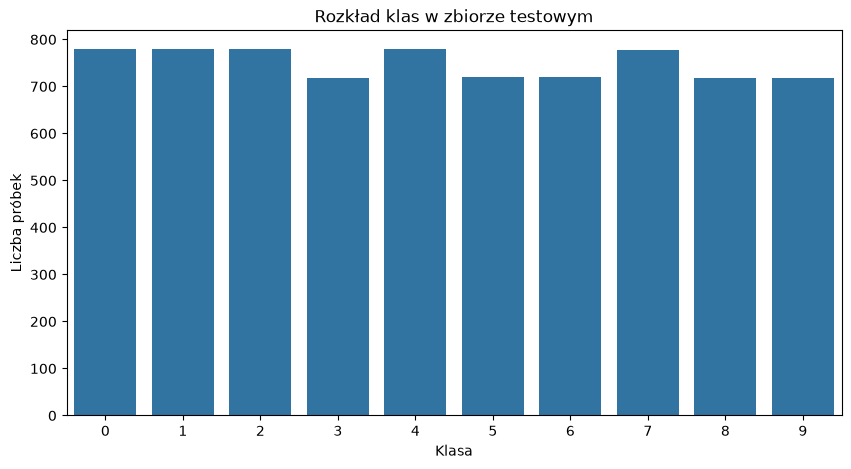

In [4]:
plt.figure(figsize=(10,5))
sns.countplot(data=df_train, x="target")
plt.title("Rozkład klas w zbiorze testowym")
plt.xlabel("Klasa")
plt.ylabel("Liczba próbek")
plt.show()

Sprawdzenie statystyk opisowych i podział danych

In [5]:
display(df_train.describe())

x_train = df_train.drop("target", axis=1)
y_train = df_train["target"]
x_test = df_test.drop("target", axis=1)
y_test = df_test["target"]

,x1,y1,x2,y2,x3,y3,x4,y4,x5,y5,x6,y6,x7,y7,x8,y8,target
count,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000
mean,37.384307,84.679343,40.005604,82.889512,50.878303,65.044436,51.471844,44.599680,57.129971,34.069122,61.417401,35.782092,54.699760,35.800774,46.813718,28.565386,4.430878
std,33.322024,16.848420,26.256025,19.638582,34.927201,27.377341,30.680075,30.659478,33.680340,27.459989,37.130762,27.495836,22.599781,33.223611,41.531794,35.811094,2.876981
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,5.000000,76.000000,20.000000,70.000000,17.000000,48.000000,28.000000,22.000000,30.000000,7.000000,25.000000,12.000000,41.000000,7.000000,0.000000,0.000000,2.000000
50%,31.000000,89.000000,39.000000,89.000000,56.000000,71.000000,54.000000,42.000000,60.000000,33.000000,74.000000,32.000000,53.000000,28.000000,39.000000,8.000000,4.000000
75%,61.000000,100.000000,58.000000,100.000000,81.000000,86.000000,75.000000,65.000000,88.000000,55.000000,98.000000,57.000000,69.000000,48.000000,100.000000,51.000000,7.000000
max,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,9.000000


## Podsumowanie i wnioski z EDA

1. **Jakość danych:**
    * Brak brakujących wartości w zbiorze treningowym i testowym.
    * Zbiór nie zawiera duplikatów.
2. **Zmienna docelowa i rozkład klas:**
    * Zmienna docelowa `target` zawiera 10 klas reprezentujących cyfry od `0` do `9`.
    * Rozkład klas w zbiorze treningowym jest zrównoważony.
3. **Struktura i zakresy cech:**
    * Dane zawierają 16 cech numerycznych odpowiadających ośmiu parom współrzędnych $(x,y)$ śledzonego ruchu pióra.
    * Zbiór testowy posiada identyczny zestaw i układ 16 cech oraz kolumnę docelową.
    * Wszystkie cechy posiadają wartości w przedziale od 0 do 100.
4. **Uzasadnienie preprocessingu:**
    * Ze względu na użycie w kolejnym kroku algorytmów wrażliwych na skalę cech (np. SVM, Regresja Logistyczna), zastosujemy **`StandardScaler`** do standaryzacji cech. Mimo spójnego zakresu wejściowego, ułatwi to optymalizację i porównywalność wag modeli.
5. **Analiza statystyk opisowych:**
    * Zbiór treningowy zawiera 7494 próbki.
    * Wszystkie cechy numeryczne posiadają minimum równe 0 oraz maksimum równe 100, co potwierdza spójną normalizację siatki pisania.
    * Cechy różnią się poziomem zmienności, niektóre mają wysoką średnią i niskie odchylenie standardowe a inne odwrotnie.

## B — Modelowanie

Zbuduj prosty model bazowy i porównaj go z kilkoma klasyfikatorami statystycznymi lub klasycznego uczenia maszynowego. Wykonaj dobór modeli, strojenie i sposób zapobiegania wyciekowi danych. 

### Cross-Validatin

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Baseline (Dummy)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, random_state=42))
    ]),
    "k-NN (k=5)": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", KNeighborsClassifier(n_neighbors=5))
    ]),
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", SVC(random_state=42))
    ]),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42)
}
results = []

for name, model in models.items():
    scores = cross_validate(
        model,
        x_train,
        y_train,
        cv=cv,
        scoring="accuracy",
        return_train_score=True,
        n_jobs=-1
    )

    results.append({
        "Model": name,
        "Dokładność (Train)": round(scores["train_score"].mean(),4),
        "Dokładność (Val)": round(scores["test_score"].mean(),4),
        "Odch. std. (Val)": round(scores["test_score"].std(),4),
        "Średni czas uczenia [s]": round(scores["fit_time"].mean(),3)
})

df_cv_results = pd.DataFrame(results)
display(df_cv_results)

,Model,Dokładność (Train),Dokładność (Val),Odch. std. (Val),Średni czas uczenia [s]
0,Baseline (Dummy),0.1041,0.1041,0.0000,0.078
1,Logistic Regression,0.9661,0.9620,0.0020,0.457
2,k-NN (k=5),0.9956,0.9924,0.0025,0.031
3,SVM,0.9975,0.9957,0.0023,0.404
4,Random Forest,1.0000,0.9917,0.0022,2.309


### Podsumowanie wstępnego porównania modeli:

1. **Baseline/DummyClassifier:** dokładność 10,41%, co odpowiada losowemu zgadywaniu dla 10 równolicznych klas.  
2. **Logisitc Regression:** dokładność 96,20% pokazuje, że większość cyfr łatwo od siebie odróżnić za pomocą prostych reguł, ale linia prosta nie wystarcza do idealnego rozróżnienia skomplikowanych kształtów cyfr.
3. **k-NN, k=5:** dokładność **99,24%** oraz bardzo szybki czas uczenia (~0.03 s). 
4. **Random Forest:** osiągnął **99,17%** na walidacji, ale 100% na zbiorze treningowym wskazuje na lekkie przeuczenie (*overfitting*). Czas uczenia był najdłuższy ze wszystkich modeli (~2.1 s).
5. **SVM z jądrem RBF:** Najwyższa dokładność walidacji krzyżowej wynosząca **99,57%** przy bardzo niskim odchyleniu standardowym ($0,0023$). Model wykazuje optymalny balans między zbiorem treningowym (99,75%) a walidacyjnym.

Wybieramy model **SVM** do dalszego strojenia hiperparametrów za pomocą `GridSearchCV`.

### Strojenie hiperparametrów dla SVM

In [7]:
pipe_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", SVC(random_state=42))
])

param_grid_svm = {
    "clf__C": [0.1, 1, 10, 50, 100],
    "clf__gamma": ["scale", "auto", 0.01, 0.1]
}

grid_search_svm = GridSearchCV(
    estimator=pipe_svm,
    param_grid=param_grid_svm,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

grid_search_svm.fit(x_train, y_train)

print("Najlepsze parametry dla SVM:", grid_search_svm.best_params_)
print(f"Najlepsza  dokładność walidacji krzyżowej: {grid_search_svm.best_score_:.4f}")

best_model = grid_search_svm.best_estimator_

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Najlepsze parametry dla SVM: {'clf__C': 10, 'clf__gamma': 0.1}
Najlepsza  dokładność walidacji krzyżowej: 0.9968


Proces strojenia siatki podniósł dokładność walidacji krzyżowej modelu SVM z poziomu **99,57%** (parametry domyślne) do **99,68%**.  
**Interpretacja parametrów:** 
  * Wybrana wartość **`C = 10`** oznacza, że algorytm nakłada większą karę na błędy klasyfikacji w zbiorze treningowym, tworząc bardziej rygorystyczne granice decyzyjne między cyframi.
  * Wybrana wartość **`gamma = 0.1`** sprawia, że pojedyncze próbki mają dość lokalny wpływ. W połączeniu z nieliniowym jądrem RBF pozwala to modelowi precyzyjnie otaczać skomplikowane i wielowymiarowe skupiska punktów (unikalne kształty trajektorii poszczególnych cyfr).

## C — Porównanie i wnioski

Porównaj modele na oficjalnym zbiorze testowym za pomocą odpowiednich metryk liczbowych. Uwzględnij błędy oraz praktyczny koszt modeli, np. czas uczenia i inferencji albo liczbę parametrów. Odpowiedz, czy wzrost złożoności jest wart uzyskanej poprawy.

Ostateczna dokładność na zbiorze testowym: 0.9806

Raport klasyfikacji:
              precision    recall  f1-score   support

           0       1.00      0.97      0.98       363
           1       0.97      0.99      0.98       364
           2       0.99      1.00      1.00       364
           3       0.97      0.99      0.98       336
           4       1.00      0.99      0.99       364
           5       0.98      0.99      0.98       335
           6       0.99      1.00      1.00       336
           7       0.99      0.92      0.95       364
           8       0.96      1.00      0.98       336
           9       0.96      0.98      0.97       336

    accuracy                           0.98      3498
   macro avg       0.98      0.98      0.98      3498
weighted avg       0.98      0.98      0.98      3498



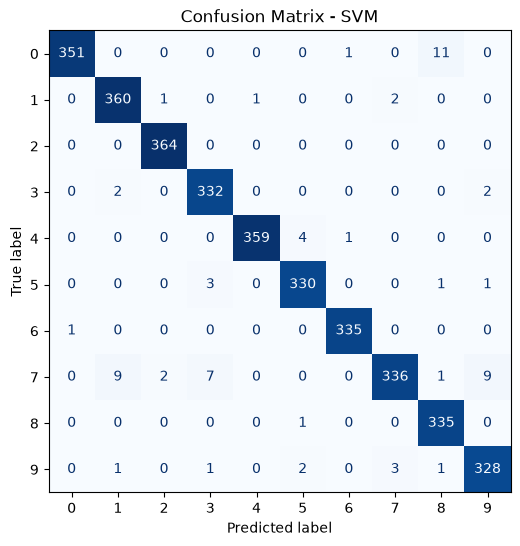

In [8]:
y_pred = best_model.predict(x_test)

test_accuracy = accuracy_score(y_test, y_pred)
print(f"Ostateczna dokładność na zbiorze testowym: {test_accuracy:.4f}\n")
print("Raport klasyfikacji:")
print(classification_report(y_test, y_pred))

fig, ax = plt.subplots(figsize=(8,6))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues",
    ax=ax,
    colorbar=False
)
plt.title("Confusion Matrix - SVM")
plt.show()


### Wnioski z ostatecznej ewaluacji

**Stabilność modelu:** Dokładność 98,06% na danych testowych jest nieznacznie niższa od walidacyjnej (99,68%), co pokazuje, że model nie uległ przeuczeniu i bardzo dobze radzi sobie z nowymi danymi.

**Analiza błędów (Confusion Matrix):**  
- Najczęstszym błędem było mylenie cyfry 0 z cyfrą 8 (11 błędnych klasyfikacji). Obie cyfry są pisane ruchem ciągłym jako zamknięte pętle, co zbliża ich trajektorie.  
- Najbardziej problematyczną cyfrą była 7, często mylona z 1 (9 pomyłek), 9 (9 pomyłek) i 3 (7 pomyłek). Wynika to ze współdzielenia prostych cięć (z 1) i ostrych kątów (z 3 i 9).   
- Cyfry takie jak 2 i 6 zostały sklasyfikowane niemal bezbłędnie na całym zbiorze testowym.

## Oddanie zadania

Zapisz kod, wyniki, wykresy i krótkie uzasadnienia w tym notatniku. Podaj użyte źródła oraz narzędzia AI i upewnij się, że notatnik można uruchomić od początku do końca. Wykonaj commit po zakończeniu zadania aby znalazł się na repozytorium.

Źródła: Wykorzystano model językowy Gemini 3.1 Pro